In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("50_Startups.csv")
data = pd.concat([data.drop("State", axis=1), pd.get_dummies(data["State"], drop_first=True)], axis=1)

train_ratio = 0.8
test_ratio = 0.2
shuffled_df = data.sample(frac=1, random_state=0).reset_index(drop=True)
split_index = int(len(shuffled_df) * train_ratio)

train_df = shuffled_df[:split_index]
test_df = shuffled_df[split_index:]

features = ["R&D Spend", "Administration", "Marketing Spend", "Florida", "New York"]
target = "Profit"

X_train = train_df[features].values
y_train = train_df[target].values
X_test = test_df[features].values
y_test = test_df[target].values

In [91]:
def linear_regression(X, y, learning_rate=0.01, epochs=1000):
    X = np.array(X, dtype=float)
    y = np.array(y, dtype=float)
    X_mean = np.mean(X, axis=0)
    X_std = np.std(X, axis=0)
    X_scaled = (X - X_mean) / (X_std + 1e-8)

    n_samples, n_features = X_scaled.shape
    m = np.zeros(n_features)
    c = 0.0
    loss_history = []

    for epoch in range(epochs):
        y_pred = np.dot(X_scaled, m) + c

        dm = (-2 / n_samples) * np.dot(X_scaled.T, (y - y_pred))
        dc = (-2 / n_samples) * np.sum(y - y_pred)

        m = m - (learning_rate * dm)
        c = c - (learning_rate * dc)

        loss = np.mean((y - y_pred) ** 2)
        loss_history.append(loss)

        print(f"Epoch {epoch:<4} | Loss: {loss:.2f}")
    final_loss = np.mean((y - (np.dot(X_scaled, m) + c)) ** 2)
    print(f"Final Loss: {final_loss:.2f}")

    return m, c, loss_history, X_mean, X_std

In [92]:
m, c, loss_history, X_mean, X_std = linear_regression(X_train, y_train, learning_rate=0.01, epochs=1000)

Epoch 0    | Loss: 14083354751.00
Epoch 1    | Loss: 13487738176.12
Epoch 2    | Loss: 12919338063.18
Epoch 3    | Loss: 12376770981.84
Epoch 4    | Loss: 11858734015.38
Epoch 5    | Loss: 11363999402.14
Epoch 6    | Loss: 10891409572.48
Epoch 7    | Loss: 10439872550.02
Epoch 8    | Loss: 10008357688.72
Epoch 9    | Loss: 9595891719.25
Epoch 10   | Loss: 9201555080.81
Epoch 11   | Loss: 8824478515.97
Epoch 12   | Loss: 8463839908.33
Epoch 13   | Loss: 8118861344.20
Epoch 14   | Loss: 7788806380.99
Epoch 15   | Loss: 7472977506.70
Epoch 16   | Loss: 7170713775.75
Epoch 17   | Loss: 6881388607.80
Epoch 18   | Loss: 6604407737.36
Epoch 19   | Loss: 6339207302.70
Epoch 20   | Loss: 6085252063.73
Epoch 21   | Loss: 5842033739.20
Epoch 22   | Loss: 5609069454.40
Epoch 23   | Loss: 5385900291.15
Epoch 24   | Loss: 5172089932.76
Epoch 25   | Loss: 4967223396.73
Epoch 26   | Loss: 4770905849.17
Epoch 27   | Loss: 4582761494.81
Epoch 28   | Loss: 4402432537.21
Epoch 29   | Loss: 4229578204.38
E

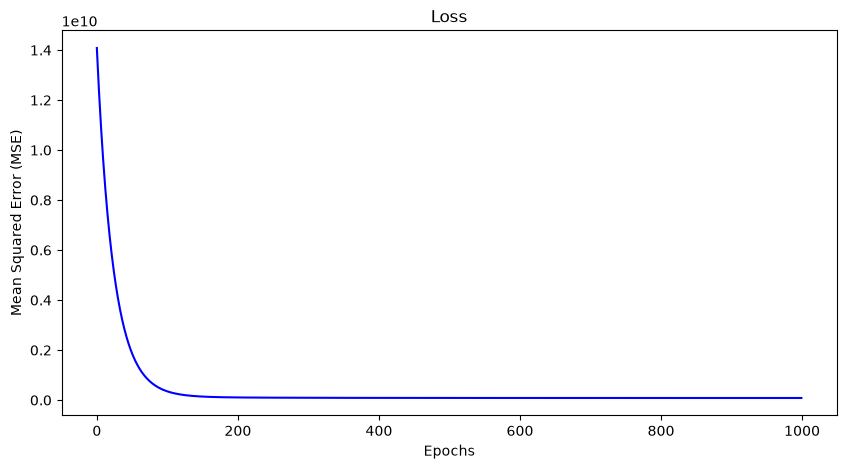

In [93]:
plt.figure(figsize=(10, 5))
plt.plot(loss_history, color='blue')
plt.title("Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error (MSE)")
plt.show()

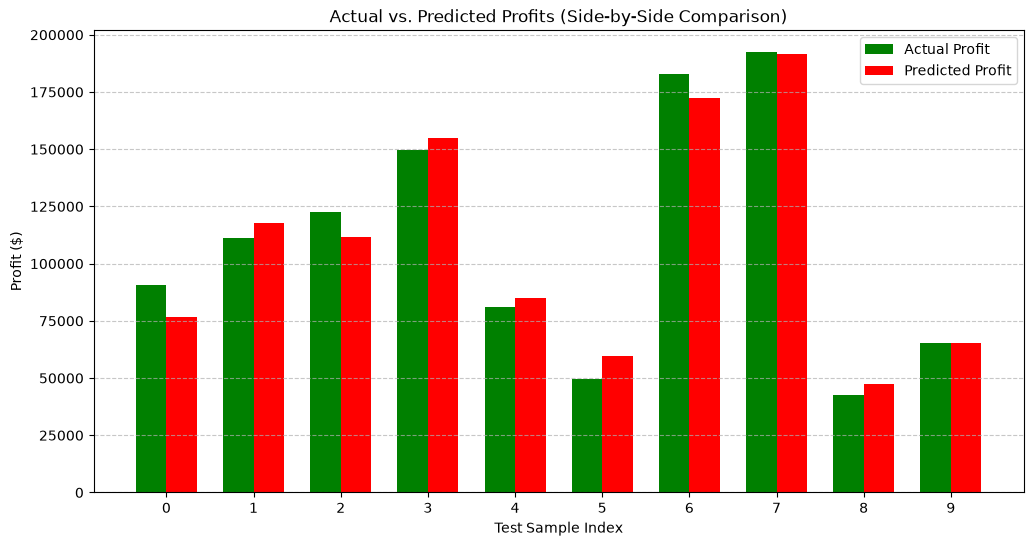

In [94]:
X_test_scaled = (X_test - X_mean) / (X_std + 1e-8)
pred_values = np.dot(X_test_scaled, m) + c

x_indices = np.arange(len(y_test))
bar_width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(x_indices - bar_width/2, y_test, width=bar_width, color='green', label="Actual Profit")
plt.bar(x_indices + bar_width/2, pred_values, width=bar_width, color='red', label="Predicted Profit")

plt.title("Actual vs. Predicted Profits (Side-by-Side Comparison)")
plt.xlabel("Test Sample Index")
plt.ylabel("Profit ($)")

plt.xticks(x_indices) 

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()